# 17 In-Class Assignment: Inner Products


<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/4e/Pleiades_large.jpg/1200px-Pleiades_large.jpg" alt="Image of the pleiades star cluster" width="50%">


Image from: https://www.wikipedia.org/    

# Siddak Marwaha

---
<a name="Pre-class_Review"></a>
## 1. Pre-class Review

An inner product on a real vector space $V$ is a function that associates a number, denoted as $\langle u,v \rangle$, with each pair of vectors $u$ and $v$ of $V$. This function satisfies the following conditions for vectors $u, v, w$ and scalar $c$:


$$\langle u,v \rangle = \langle v,u \rangle \text{ symmetry axiom}$$ 

$$\langle u+v,w \rangle = \langle u,w \rangle + \langle v,w \rangle \text{ additive axiom}$$ 

$$\langle cu,v \rangle = c\langle u,v \rangle \text{ homogeneity axiom}$$ 

$$\langle u,u \rangle \ge 0 \text{ and } \langle u,u \rangle = 0 \text{ if and only if } u = 0 \text{ positive definite axiom}$$ 


The dot product of $R^n$ is an inner product. However, we can define many other inner products.

### Norm of a vector

Let $V$ be an inner product space. The norm of a vector $v$ is denoted $\lVert v \rVert$ and is defined by:

$$\lVert v \rVert = \sqrt{\langle v,v \rangle}$$

### Angle between two vectors

Let $V$ be a real inner product space. The angle $\theta$ between two nonzero vectors $u$ and $v$ in $V$ is given by:

$$cos(\theta) = \frac{\langle u,v \rangle}{\lVert u \rVert \lVert v \rVert}$$

### Orthogonal Vectors

Let $V$ be an inner product space.  Two vectors $u$ and $v$ in $V$ are orthogonal if their inner product is zero:

$$\langle u,v \rangle = 0$$

### Distance
Let $V$ be an inner product space. The distance between two vectors (points) $u$ and $v$ in $V$ is denoted $d(u,v)$ and is defined by:

$$d(u,v) = \lVert u-v \rVert = \sqrt{\langle u-v, u-v \rangle}$$

---
<a name="Minkowski_Geometry"></a>
## 2. Minkowski Geometry
Consider the following pseudo inner-product which is used to model special relativity in $\mathbb{R}^4$:

$$\langle X,Y \rangle = -x_1y_1 - x_2y_2 -x_3y_3 + x_4y_4$$

It has the following norms and distances:

$$\lVert X \rVert = \sqrt{|\langle X,X \rangle|}$$

$$ d(X,Y) = \lVert X - Y \rVert = \lVert ( x_1 - y_1, x_2-y_2, x_3 - y_3, x_4 - y_4) \rVert$$

$$ = \sqrt{|-(x_1 - y_1)^2 - (x_2-y_2)^2 - (x_3 - y_3)^2 + (x_4 - y_4)^2|}$$

&#9989;**<font color=red>QUESTION:</font>** The Minkowski Geometry is called pseudo inner product because it violates one of the inner product axioms. Discuss the axioms in your group and decide which one it violates.

**Positive definite axiom**

---
<a name="Function_Approximation"></a>
## 3. Polynomial Approximation

In many scientific problems, it is desireable to approximate a complicated function by a simpler function. One common choice is to approximate the function of interest $f(x)$ by a low-degree polynomial, i.e. $$f(x) \approx a_0 + a_1x + a_2x^2 + \cdots + a_dx^d.$$  

Our goal in this part of the ICA, is to approximate the function $f(x) = \text{arctan}(2x)$ over $x \in [-1,1]$ by a low-degree polynomial. We will try two methods:
1. The order-$d$ Taylor polynomial
2. The orthogonal projection onto the subspace of polynomials with degree $\le d$

We will be doing symbolic computations using SymPy. To start, run the cell below.

In [1]:
import sympy as sym

# Create symbolic variable x so that SymPy can do symbolic calculations with x as a variable
x = sym.symbols('x')

### 3.1 Taylor Polynomial

If $f(x)$ is infinitely differentiable at $x = 0$, then, the Taylor series of $f(x)$ at $x = 0$ is given by 

$$\sum_{k = 0}^{\infty}\dfrac{f^{(k)}(0)}{k!}x^k$$

If we then truncate this series to $d+1$ terms, we obtain the Taylor polynomial of order $d$: 

$$T_d(x) = \sum_{k = 0}^{d}\dfrac{f^{(k)}(0)}{k!}x^k$$

Under certain conditions, one can approximate a function by it's order-$d$ Taylor polynomial, $f(x) \approx T_d(x)$, for some small value of $d$.

Before we try approximating $f(x) = \arctan(2x)$, let's look at a different function $e^{2x}$. The Taylor series for this function is 

$$\sum_{k = 0}^{\infty}\dfrac{2^k}{k!}x^k = 1 + 2x + 2x^2 + \dfrac{4}{3}x^3 + \cdots.$$

The code below uses SymPy to compute the order-$d$ Taylor polynomial for the function $e^{2x}$, and it creates a plot of $e^{2x}$ (in blue) and the order-$d$ Taylor polynomial (in red) over $x \in [-1,1]$. Initially, we set $d = 1$.

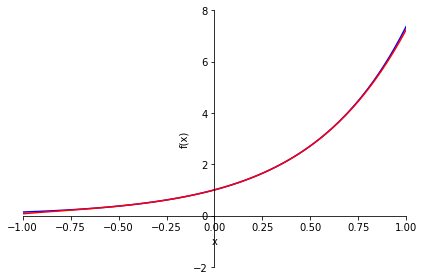

In [5]:
# Define symbolic function for e^(2x)
exp2x = sym.exp(2*x)

# Define symbolic function for order-d Taylor polynomial
d = 5
exp2xTaylor = 0
for k in range(d+1):
    exp2xTaylor += (2**k/sym.factorial(k))*x**k

# Make plot
p = sym.plot(exp2x,exp2xTaylor,(x,-1,1),xlim=(-1,1),ylim=(-2,8),show=False)
p[0].line_color = 'blue'
p[1].line_color = 'red'
p.show()

&#9989;**<font color=red>DO THIS:</font>** Qualitatively, how good of an approximation is the order-$1$ Taylor polynomial for $x$ near $0$? How does the quality of the approximation change as $x$ gets further away from $0$? 

**near 0, it is almost the same. As x gets away from 0, the approximation gets worse.**

&#9989;**<font color=red>DO THIS:</font>** Try increasing the degree $d$ of the Taylor polynomial above, and qualitatively explain how the approximation changes as $d$ increases. How large does $d$ need to be before the degree-$d$ Taylor polynomial appears to be a good approximation of $e^{2x}$ on $[-1,1]$?

**as d increases, the approximation comes closer to the real values. d = 5.**

You should have observed that a fairly low degree Taylor polynomial does a good job approximating $e^{2x}$ over the entire interval $[-1,1]$.

But now, let's see what happens with the function $f(x) = \arctan(2x)$, whose Taylor series is 

$$\sum_{\substack{k = 0\\k\text{ is odd}}}^{\infty}\dfrac{(-1)^{\tfrac{k-1}{2}}2^{k}}{k}x^{k} = 2x - \dfrac{8}{3}x^3 + \dfrac{32}{5}x^5 - \dfrac{128}{7}x^7 + \cdots.$$

Note that $\arctan(2x)$ is an odd function, so the even terms of this Taylor series are zero.

The code below computes the order-$d$ Taylor polynomial, $T_d(x)$, for the function $f(x) = \arctan(2x)$ and makes a plot of $f(x)$ (in blue) and $T_d(x)$ (in red) over $x \in [-1,1]$.

<a name="Plot"></a>

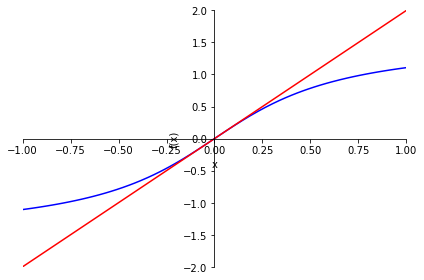

In [64]:
# Define symbolic function for f(x) = arctan(2x)
f = sym.atan(2*x)

# Define symbolic function for order-d Taylor polynomial T_d(x)
d = 1
Td = 0
for k in range(d+1):
    if(sym.Mod(k,2)==1):
        Td += (((-1)**((k-1)/2))*(2**k)/k)*x**k

# Make plot
p = sym.plot(f,Td,(x,-1,1),xlim=(-1,1),ylim=(-2,2),show=False)
p[0].line_color = 'blue'
p[1].line_color = 'red'
p.show()

&#9989;**<font color=red>DO THIS:</font>** You should notice that for $d = 1$, $T_d(x)$ is a good approximation for $f(x)$ near $x = 0$, but a bad approximation further away from $x = 0$. Again, try increasing the degree $d$ of the polynomial, and qualitatively explain how the approximation changes as $d$ increases. As $d$ gets larger, does $T_d(x)$ become a better approximation of $f(x)$ over the entire interval $[-1,1]$? If not, over what range is it good for?

**Approximation does not really come closer as d increases now. It just changes shape. In fact, it does that periodically as well. Its good for d = 1-6**

### 3.2 Orthogonal Projection onto a Subspace

Now, we will cast the problem of finding a polynomial to approximate a function into the language of linear algebra, and use tools we've already learned to solve this problem. 

Recall that if $W$ is a subspace of $\mathbb{R}^n$, and $\{\vec{u}_1,\vec{u}_2,\ldots,\vec{u}_m\}$ is an orthonormal basis for $W$, then the projection of a vector $\vec{x} \in \mathbb{R}^n$ onto the subspace $W$ is defined by 

$$\text{proj}_W\vec{x} = (\vec{x}\cdot\vec{u}_1)\vec{u}_1 + (\vec{x}\cdot\vec{u}_2)\vec{u}_2 + \cdots + (\vec{x}\cdot\vec{u}_m)\vec{u}_m$$

Note that the vector $\text{proj}_W \vec{x}$ is the closest vector in $W$ to $\vec{x}$, i.e., over all vectors $\vec{y} \in W$, the quantity $\|\vec{x}-\vec{y}\|$ is minimized for $\vec{y} = \text{proj}_W \vec{x}$.

So far in this course, the most common vector space we've worked with is $\mathbb{R}^n$, but remember that other things can be vector spaces. Furthermore, the concept of a projection onto a subspace can be generalized to other vector spaces. 



**Definition:** Let $C[-1,1]$ be the vector space of all continuous functions over the interval $[-1,1]$. 

We can define the following inner product over $C[-1,1]$:

$$\langle f,g \rangle = \int_{-1}^{1} f(x)g(x)\,dx.$$

The norm induced by this inner product is 

$$\|f\| = \sqrt{\langle f,f \rangle} = \left(\int_{-1}^{1} f(x)^2\,dx\right)^{1/2}.$$

If $f$ is a function in $C[-1,1]$, $W$ is a subspace of $C[-1,1]$, and $\{u_1,u_2,\ldots,u_m\}$ are functions that form an orthonormal basis for $W$, then we can define the projection of $f$ onto $W$ by 

$$\text{proj}_Wf = \langle f,u_1 \rangle u_1 + \langle f,u_2 \rangle u_2 + \cdots + \langle f,u_m \rangle u_m.$$ 

This is analogous to the definition of the projection of a vector onto a subspace of $\mathbb{R}^n$, except the vectors are now functions and the dot products are now inner products.

Again, the function $\text{proj}_Wf$ is the closest function in $W$ to $f$, i.e., over all functions $g \in W$, the quantity 

$$\|f-g\|^2 = \int_{-1}^{1}\left(f(x)-g(x)\right)^2\,dx$$ 

is minimized for $g = \text{proj}_Wf$.

In order to use projections to find a polynomial of degree $\le d$ that approximates $f(x) = \arctan(2x)$, we need to check that the set of polynomials of degree $\le d$ form a subspace of $C[-1,1]$.

&#9989;**<font color=red>DO THIS:</font>** Explain why the set of polynomials of degree $\le d$, i.e., 

$$W_d = \{a_0+a_1x+a_2x^2+\cdots+a_dx^d \ | \ a_0,a_1,a_2,\ldots,a_d \in \mathbb{R}\}$$ 

is a subspace of $C[-1,1]$.

**The set of polynomials of degree $\le d$, denoted as $W_d$, is a subspace of $C[-1,1]$ because it satisfies the three conditions required for a subset to be considered as a subspace: Closed under addition, Closed under scalar multiplication, Contains the zero vector**

Now that we've checked that $W_d$ is a subspace of $C[-1,1]$, we can find a polynomial $P_d$ of degree $\le d$ which makes 

$$\|f-P_d\|^2 = \int_{-1}^{1}\left(f(x)-P_d(x)\right)^2\,dx$$ 

as small as possible by computing the projection of $f(x)$ onto the subspace $W_d$, i.e. $P_d = \text{proj}_{W_d} f$. 

To do this, we will need to form an orthonormal basis for $W_d$.

&#9989;**<font color=red>DO THIS:</font>** Explain why the set of functions $\{1, x, \ldots, x^d\}$ form a basis for $W_d$.

**It's linearly independent and spans the set.**

&#9989;**<font color=red>DO THIS:</font>** Explain why the set of functions $\{ 1, x, \ldots, x^d \}$ is NOT an orthonormal basis for $W_d$. 

Hint: Recall that an orthonormal basis must satisfy $\langle u_i,u_i \rangle = \|u_i\|^2 = 1$ for all $i$, and $\langle u_i,u_j \rangle = 0$ for $i \neq j$.

**TO check orthogonality, inner product of 1 and x^2 = 2/3 ≠ 0 hence not orthogonal**

### Gram-Schmidt

Given a basis for a subspace $W$ of a vector space $V$, we can obtain an orthonormal basis for $W$ using the Gram-Schmidt process (just like we did to convert a basis for a subspace of $\mathbb{R}^n$ into an orthonormal basis).

Recall that the Gram-Schmidt algorithm can be described by the following pseudocode

Given a basis $\{v_0,v_1,\ldots,v_m\}$ for $W$.

For $k = 0, 1, \ldots, m$:

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $u_k = v_k$ &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; (Start by setting the new vector $u_k$ equal to $v_k$)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; For $j = 0, 1, \ldots, k-1$:  

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $u_k = u_k - \langle v_k,u_j\rangle u_j$ &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; (Make the new vector $u_k$ orthogonal to $u_j$)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $u_k = \dfrac{u_k}{\|u_k\|}$ &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; (Make the new vector $u_k$ a unit vector)

Output: An orthonormal basis $\{u_0,u_1,\ldots,u_m\}$ for $W$.

&#9989;**<font color=red>DO THIS:</font>** Complete the code below to perform the Gram-Schmidt procedure on the basis $\{1,x,x^2,\ldots,x^7\}$ to obtain an orthonormal basis $\{u_0,u_1,u_2,\ldots,u_7\}$.
* The code below defines `x` to be a variable that `SymPy` can do symbolic calculations with. 
* The Python method `inner_prod()` symbolically computes the inner product of two symbolic functions `f` and `g`.
* The $k$-th element of the list `v` has $v_k = x^k$ as a symbolic object
* The $k$-th element of the list `u` will be a symbolic object for $u_k$, i.e., the $k$-th element of the orthonormal basis.

In [47]:
# This computes the inner product of symbolic functions f and g
def inner_prod(f,g):
    return sym.integrate(f*g,(x,-1,1))

m = 7
# This makes a list of symbolic functions for powers of x: v = [1,x,x^2,...,x^m]
v = []
for k in range(m+1):
    v.append(x**k)

# Implement the Gram-Schmidt procedure to make a list with the orthonormal basis elements: u = [u_0,u_1,...,u_m]
u = []
for k in range(m+1):
    uk = v[k] ########## Fix this line to initialize u_k = v_k
    for j in range(k): 
        uk -= inner_prod(v[k], u[j]) * u[j] ########## Fix this line to make u_k orthogonal to u_j
    uk = uk/sym.sqrt(inner_prod(uk, uk)) ########## Fix this line to scale u_k to make it a unit vector
    u.append(uk) # Add u_k to the list u

# This part prints out the orthonormal basis {u_0,u_1,...,u_m}
for k in range(m+1):
    print("u["+str(k)+"] =",u[k])

u[0] = sqrt(2)/2
u[1] = sqrt(6)*x/2
u[2] = 3*sqrt(10)*(x**2 - 1/3)/4
u[3] = 5*sqrt(14)*(x**3 - 3*x/5)/4
u[4] = 105*sqrt(2)*(x**4 - 6*x**2/7 + 3/35)/16
u[5] = 63*sqrt(22)*(x**5 - 10*x**3/9 + 5*x/21)/16
u[6] = 231*sqrt(26)*(x**6 - 15*x**4/11 + 5*x**2/11 - 5/231)/32
u[7] = 429*sqrt(30)*(x**7 - 21*x**5/13 + 105*x**3/143 - 35*x/429)/32


If you did the above part correctly, you should get the following polynomials in the orthonormal basis:

`u[0] = sqrt(2)/2`

`u[1] = sqrt(6)*x/2`

`u[2] = 3*sqrt(10)*(x**2 - 1/3)/4`

`u[3] = 5*sqrt(14)*(x**3 - 3*x/5)/4`

`u[4] = 105*sqrt(2)*(x**4 - 6*x**2/7 + 3/35)/16`

`u[5] = 63*sqrt(22)*(x**5 - 10*x**3/9 + 5*x/21)/16`

`u[6] = 231*sqrt(26)*(x**6 - 15*x**4/11 + 5*x**2/11 - 5/231)/32`

`u[7] = 429*sqrt(30)*(x**7 - 21*x**5/13 + 105*x**3/143 - 35*x/429)/32`

&#9989;**<font color=red>DO THIS:</font>** Verify that the Gram-Schmidt procedure actually returned an orthonormal basis by checking that $$\langle u_i, u_j \rangle = \begin{cases}1 & \text{if } i = j \\ 0 & \text{if } i \neq j\end{cases}$$ for all $i, j = 0, \ldots, 7$.

In [52]:
G = sym.zeros(m+1,m+1)
########## Write a for loop over all indices i 
for i in range(8):
    ########## Write a for loop over all indices j
    for j in range(8):
        G[i,j] = inner_prod(u[i],u[j])########## Store the inner product <u_i,u_j> as the (i,j)-th entry of the Matrix G
G # Display G so you can see if the basis is orthonormal (G should be the 8x8 identity matrix)

Matrix([
[1, 0, 0, 0, 0, 0, 0, 0],
[0, 1, 0, 0, 0, 0, 0, 0],
[0, 0, 1, 0, 0, 0, 0, 0],
[0, 0, 0, 1, 0, 0, 0, 0],
[0, 0, 0, 0, 1, 0, 0, 0],
[0, 0, 0, 0, 0, 1, 0, 0],
[0, 0, 0, 0, 0, 0, 1, 0],
[0, 0, 0, 0, 0, 0, 0, 1]])

### Orthogonal Projection onto $W$

By running Gram-Schmidt on the functions $\{1,x,x^2,\ldots,x^7\}$, not only is $\{u_0,u_1,u_2,\ldots,u_7\}$ an orthonormal basis for $\text{span}\{1,x,x^2,\ldots,x^7\} = W_7$, but we also have that:
* $\{u_0\}$ is an orthonormal basis for $\text{span}\{1\} = W_0$ (constant functions)
* $\{u_0,u_1\}$ is an orthonormal basis for $\text{span}\{1,x\} = W_1$ (linear functions)
* $\{u_0,u_1,u_2\}$ is an orthonormal basis for $\text{span}\{1,x,x^2\} = W_2$ (polynomials of degree $\le 2$)
* ...
* $\{u_0,u_1,u_2,\ldots,u_6\}$ is an orthonormal basis for $\text{span}\{1,x,x^2,\ldots,x^6\} = W_6$ (polynomials of degree $\le 6$)

&#9989;**<font color=red>DO THIS:</font>** Now that we have an orthonormal basis $\{u_0,u_1,\ldots,u_d\}$ for $W_d$ (for $d = 0,1,\ldots,7$), we can compute a degree $\le d$ polynomial $P_d(x)$ that approximates $f(x)$ using the formula 

$$P_d = \text{proj}_{W_d}f = \langle f,u_0 \rangle u_0 + \langle f,u_1 \rangle u_1 + \cdots + \langle f,u_d \rangle u_d.$$ 

Complete the code below to compute the projection $P_d = \text{proj}_{W_d}f$ using the above formula, and then plot $f(x) = \arctan(2x)$ and $P_d(x)$ over the interval $[-1,1]$.

In [53]:
f

atan(2*x)

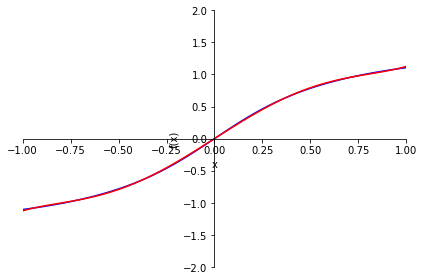

In [70]:
# Create symbolic function for P_d(x)
d = 5
Pd = 0
########## Put code here to implement the formula for proj_{W_d} f (Hint: You may need a for loop)
for i in range(d+1):
    Pd += inner_prod(f, u[i])*u[i]
# Make Plot
p = sym.plot(f,Pd,(x,-1,1),xlim=(-1,1),ylim=(-2,2),show=False)
p[0].line_color = 'blue'
p[1].line_color = 'red'
p.show()

&#9989;**<font color=red>DO THIS:</font>** For $d = 1$, compare the Taylor polynomial $T_d(x)$ with the orthogonal projection $P_d(x)$, i.e., compare [the second plot in Section 3.1](#Plot) with the above plot where d is set to be 1 in both plots. Answer the following questions:

* Is the Taylor polynomial $T_d(x)$ or the orthogonal projection $P_d(x)$ a better approximation when $x$ is near $0$? 
* Is the Taylor polynomial $T_d(x)$ or the orthogonal projection $P_d(x)$ a better approximation when $x$ is further away from $0$?

**Near 0, Taylor polynomial is a better approximation. When x is further away, orthogonal projection is a better approximation.**

&#9989;**<font color=red>DO THIS:</font>** Again, try changing the degree-$d$ of the polynomial. As $d$ gets larger, does $P_d(x)$ become a better approximation of $f(x)$ over the entire interval $[-1,1]$, or just part of $[-1,1]$? How large does $d$ need to be for $P_d(x)$ to be a good approximation of $f(x) = \arctan(2x)$?

Note: This part may be slow on your computer, so try $d = 1$, then $d = 2$, etc., and stop if it is taking too long to run.

**Yes. Pd becomes a better approximation when d is increased over all of [-1,1]. I think d = 5 is a really good approximation.**

&#9989;**<font color=red>DO THIS:</font>** You might have noticed that $P_1(x) = P_2(x)$, $P_3(x) = P_4(x)$ etc., i.e. increasing an odd $d$ by $1$ doesn't change the best approximation $P_d(x)$. Can you explain why that is the case?

**Yes, because it's an odd function. So the even terms of the Taylor series are zero.**

----

Written by Dr. Dirk Colbry and Dr. Santhosh Karnik, Michigan State University
<a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/"><img alt="Creative Commons License" style="border-width:0" src="https://i.creativecommons.org/l/by-nc/4.0/88x31.png" /></a><br />This work is licensed under a <a rel="license" href="http://creativecommons.org/licenses/by-nc/4.0/">Creative Commons Attribution-NonCommercial 4.0 International License</a>.